Number of clusters: 7
Number of noise/outliers: 35


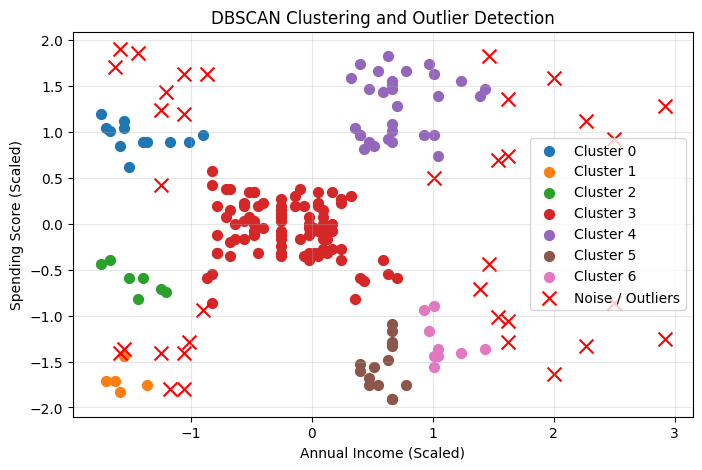

In [3]:
# 1. Load Dataset and Scale Features
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

url = "https://raw.githubusercontent.com/MahimaSriK/Mall-Customer-Segmentation-Dataset/main/Mall_Customers.csv"
df = pd.read_csv(url)

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Apply DBSCAN Clustering
model = DBSCAN(eps=0.3, min_samples=5)
labels = model.fit_predict(X_scaled)

# 3. Count Clusters and Outliers
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_outliers = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise/outliers:", n_outliers)

# 4. Visualize Clusters and Outliers
plt.figure(figsize=(8, 5))

for cluster in set(labels):
    mask = labels == cluster

    if cluster == -1:
        plt.scatter(
            X_scaled[mask, 0], X_scaled[mask, 1],
            color='red', marker='x', s=100,
            label='Noise / Outliers'
        )
    else:
        plt.scatter(
            X_scaled[mask, 0], X_scaled[mask, 1],
            s=50, label=f'Cluster {cluster}'
        )

plt.xlabel('Annual Income (Scaled)')
plt.ylabel('Spending Score (Scaled)')
plt.title('DBSCAN Clustering and Outlier Detection')
plt.legend()
plt.grid(alpha=0.3)
plt.show()